# 04 · Clustering

Do oil beta and point-in-time fundamentals rediscover the five segments? Features are z-scored. Missing ratios are imputed with the **universe** median (not the segment median, which would leak the answer) and every imputed cell is flagged. A complete-case run is the check.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.analysis import clustering
raw, z, seg, imputed = clustering.feature_matrix()
raw.assign(segment=seg)

,oil_beta,capex_intensity,reinvestment_rate,fcf_yield,debt_to_capital,payout_ratio,segment
ticker,,,,,,,
XOM,0.297,0.085,0.546,0.032,0.144,0.722,majors
CVX,0.303,0.092,0.511,0.037,0.176,0.732,majors
COP,0.453,NaN,NaN,NaN,0.266,0.455,majors
EOG,0.450,0.270,0.609,0.047,0.210,0.470,upstream
DVN,0.598,0.209,0.535,0.057,0.351,0.249,upstream
FANG,0.566,0.234,0.402,0.093,0.271,NaN,upstream
OXY,0.495,0.298,0.610,0.065,0.383,0.151,upstream
APA,0.644,NaN,0.603,0.104,0.424,NaN,upstream
KMI,0.240,0.179,0.511,0.038,0.497,0.440,midstream


In [3]:
imputed.sum().rename('imputed cells')

oil_beta             0
capex_intensity      4
reinvestment_rate    3
fcf_yield            3
debt_to_capital      0
payout_ratio         3
Name: imputed cells, dtype: int64

In [4]:
res = clustering.compute()
pd.DataFrame(res['silhouette_by_k'])

,kmeans,ward
2,0.279,0.279
3,0.289,0.289
4,0.228,0.228
5,0.274,0.274
6,0.307,0.307


In [5]:
pd.DataFrame({n: {'silhouette': v['silhouette'], 'ARI vs segments': v['adjusted_rand_vs_segments']} for n, v in res['k5'].items()})

,kmeans,ward
silhouette,0.274,0.274
ARI vs segments,0.612,0.612


In [6]:
pd.DataFrame({'segment': seg, 'kmeans': res['k5']['kmeans']['assignments'], 'ward': res['k5']['ward']['assignments']}).sort_values('kmeans')

,segment,kmeans,ward
MPC,refiners,0,0
ET,midstream,0,0
OKE,midstream,0,0
KMI,midstream,0,0
COP,majors,1,2
SLB,services,1,2
BKR,services,1,2
HAL,services,1,2
DVN,upstream,2,3
OXY,upstream,2,3


In [7]:
res['complete_case']

{'n_companies': 12,
 'dropped': ['APA', 'COP', 'ET', 'FANG', 'PSX', 'VLO'],
 'kmeans_k5_adjusted_rand': 0.7642857142857142}

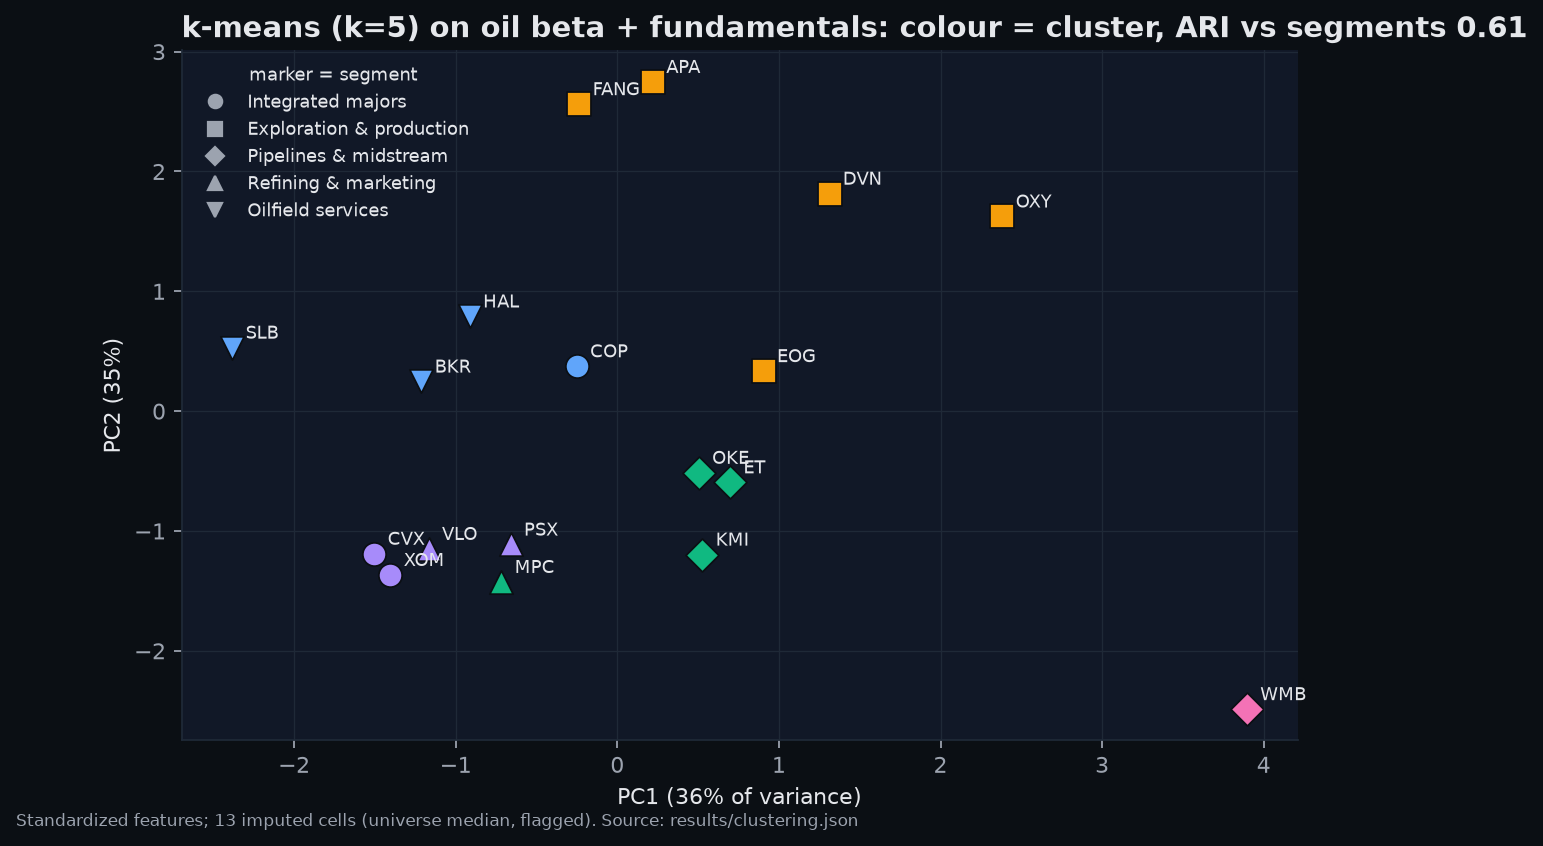

In [8]:
Image('../docs/img/clusters.png')

In [9]:
display(Markdown(f"**Takeaway.** Clusters recover the segments only partly (ARI {res['k5']['kmeans']['adjusted_rand_vs_segments']:.2f}): producers group cleanly, while majors land with refiners on low leverage and high payouts, and WMB stands alone as the most levered, highest-reinvestment name."))

**Takeaway.** Clusters recover the segments only partly (ARI 0.61): producers group cleanly, while majors land with refiners on low leverage and high payouts, and WMB stands alone as the most levered, highest-reinvestment name.